### Import the necessary libraries

In [68]:
# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Display all dataset columns
pd.set_option("display.max_columns", None)

# Make experiments reproducible
RANDOM_STATE = 42


### load the dataset

In [69]:
from pathlib import Path

# Specify dataset location
DATA_PATH = Path(
    r"C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project"
    r"\personal_finance_system\machine_learning\dataset\raw\student_spending (1).csv"
)

# Load the dataset
df = pd.read_csv(DATA_PATH)

# Display the first five records
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


Dataset shape: (1000, 18)


### Data Cleaning - Done to ensure that data is consistent 

In [70]:
# Preserve the original dataset
df_clean = df.copy()

# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Rename the exported index
df_clean = df_clean.rename(
    columns={"Unnamed: 0": "student_id"}
)

# Check missing values
print("Missing values:")
print(df_clean.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check data types
df_clean.info()

# Display the first five records of the cleaned dataset
display(df_clean.head())

Missing values:
student_id                  0
age                         0
gender                      0
year_in_school              0
major                       0
monthly_income              0
financial_aid               0
tuition                     0
housing                     0
food                        0
transportation              0
books_supplies              0
entertainment               0
personal_care               0
technology                  0
health_wellness             0
miscellaneous               0
preferred_payment_method    0
dtype: int64
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   student_id                1000 non-null   int64
 1   age                       1000 non-null   int64
 2   gender                    1000 non-null   str  
 3   year_in_school            1000 non-null   str  


,student_id,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


### Ensure that the financial amounts are numerical and non-negative

In [71]:
# Identify financial variables
financial_cols = [
    "monthly_income", "financial_aid", "tuition",
    "housing", "food", "transportation",
    "books_supplies", "entertainment",
    "personal_care", "technology",
    "health_wellness", "miscellaneous"
]

# Convert financial values to numeric
for col in financial_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Identify missing values after conversion
print(df_clean[financial_cols].isna().sum())

# Identify negative financial values
print((df_clean[financial_cols] < 0).sum())

monthly_income     0
financial_aid      0
tuition            0
housing            0
food               0
transportation     0
books_supplies     0
entertainment      0
personal_care      0
technology         0
health_wellness    0
miscellaneous      0
dtype: int64
monthly_income     0
financial_aid      0
tuition            0
housing            0
food               0
transportation     0
books_supplies     0
entertainment      0
personal_care      0
technology         0
health_wellness    0
miscellaneous      0
dtype: int64


### Looking through the income and expenditure in the dataset

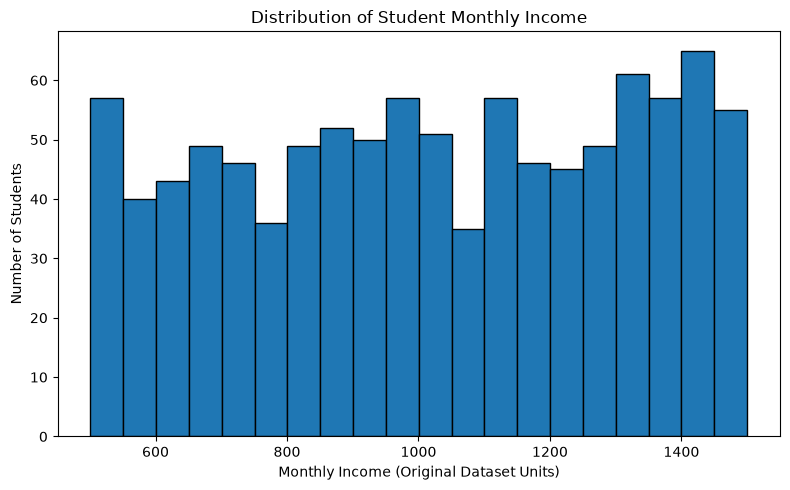

In [72]:
# Visualize the distribution of monthly income
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["monthly_income"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Student Monthly Income")
plt.xlabel("Monthly Income (Original Dataset Units)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

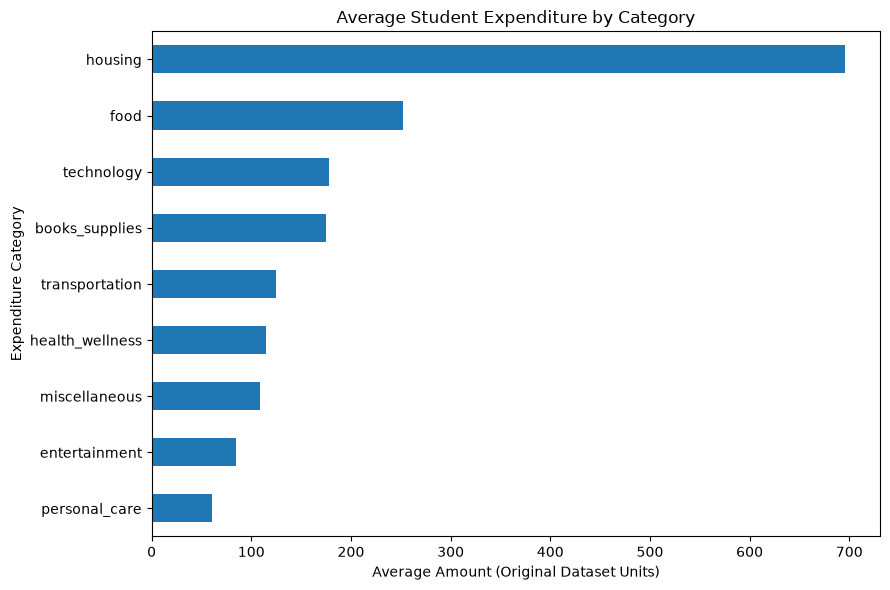

In [73]:
# Identify non-tuition expenditure categories
expense_cols = [
    "housing", "food", "transportation",
    "books_supplies", "entertainment",
    "personal_care", "technology",
    "health_wellness", "miscellaneous"
]

# Calculate average recorded expenses
average_expenses = (
    df_clean[expense_cols]
    .mean()
    .sort_values()
)

# Plot the expenditure categories
plt.figure(figsize=(9, 6))

average_expenses.plot(kind="barh")

plt.title("Average Student Expenditure by Category")
plt.xlabel("Average Amount (Original Dataset Units)")
plt.ylabel("Expenditure Category")

plt.tight_layout()
plt.show()

### Feature engineering - to create new variables from existing ones to help the model undertstand the student financial behaviour

In [74]:
#Calculate the total recorded expenses
# Sum the recorded non-tuition expenses
df_clean["total_expenses"] = df_clean[expense_cols].sum(axis=1)

# Preview the new column
display(df_clean[[
    "student_id", "monthly_income", "total_expenses"
]].head())

,student_id,monthly_income,total_expenses
0,0,958,1768
1,1,1006,1848
2,2,734,1759
3,3,617,1730
4,4,810,1941


In [75]:
#Calculate essential and discretionary expenses
# Categories treated as essential
essential_cols = [
    "housing", "food", "transportation",
    "books_supplies", "health_wellness"
]

# Categories treated as discretionary
discretionary_cols = [
    "entertainment", "personal_care",
    "technology", "miscellaneous"
]

# Calculate essential expenses
df_clean["essential_expenses"] = (
    df_clean[essential_cols].sum(axis=1)
)

# Calculate discretionary expenses
df_clean["discretionary_expenses"] = (
    df_clean[discretionary_cols].sum(axis=1)
)

# Preview the results
display(df_clean[[
    "essential_expenses",
    "discretionary_expenses"
]].head())

,essential_expenses,discretionary_expenses
0,1443,325
1,1388,460
2,1234,525
3,1383,347
4,1630,311


In [76]:
#Calculate financial ratios
# Prevent division by zero
income = df_clean["monthly_income"].replace(0, np.nan)
expenses = df_clean["total_expenses"].replace(0, np.nan)

# Spending relative to monthly income
df_clean["spending_ratio"] = (
    df_clean["total_expenses"] / income
)

# Proportion spent on discretionary items
df_clean["discretionary_ratio"] = (
    df_clean["discretionary_expenses"] / expenses
)

# Proportion spent on essential items
df_clean["essential_ratio"] = (
    df_clean["essential_expenses"] / expenses
)

# Preview financial indicators
display(df_clean[[
    "spending_ratio",
    "discretionary_ratio",
    "essential_ratio"
]].head())

,spending_ratio,discretionary_ratio,essential_ratio
0,1.845511,0.183824,0.816176
1,1.836978,0.248918,0.751082
2,2.396458,0.298465,0.701535
3,2.803890,0.200578,0.799422
4,2.396296,0.160227,0.839773


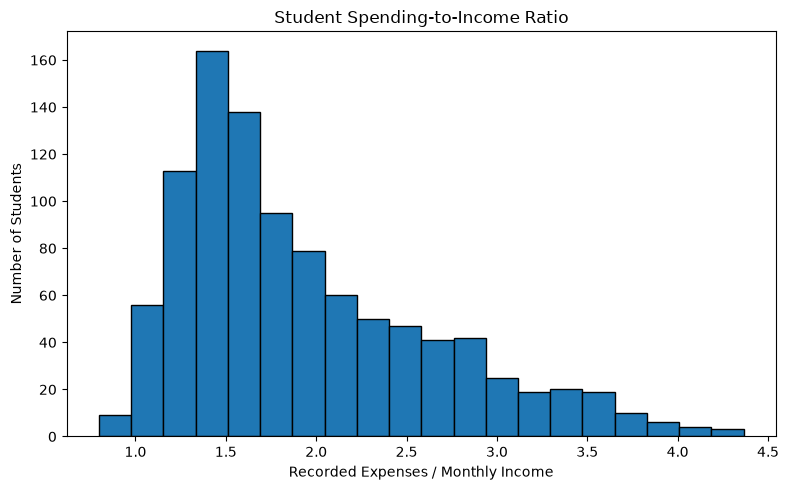

In [77]:
# Plot the spending-to-income ratios
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["spending_ratio"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Student Spending-to-Income Ratio")
plt.xlabel("Recorded Expenses / Monthly Income")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

### Check the financial data before classification

In [78]:
# Summarize key financial indicators
summary_cols = [
    "monthly_income",
    "total_expenses",
    "spending_ratio",
    "discretionary_ratio"
]

display(df_clean[summary_cols].describe().round(2))

# Count students whose expenses exceed income
above_income = (df_clean["spending_ratio"] > 1).sum()

print("Students with expenses above income:", above_income)
print("Total students:", len(df_clean))

,monthly_income,total_expenses,spending_ratio,discretionary_ratio
count,1000.00,1000.00,1000.00,1000.00
mean,1020.65,1795.08,1.94,0.24
std,293.84,238.50,0.70,0.05
min,501.00,1055.00,0.80,0.09
25%,770.75,1622.00,1.40,0.21
50%,1021.00,1784.00,1.73,0.24
75%,1288.25,1968.50,2.34,0.28
max,1500.00,2453.00,4.37,0.42


Students with expenses above income: 986
Total students: 1000


In [79]:
# Save the prepared dataset
# Create the processed-data folder
OUTPUT_DIR =  Path(
    r"C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project"
    r"\personal_finance_system\machine_learning\dataset\processed"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
df_clean.to_csv(
    OUTPUT_DIR / "student_spending_prepared.csv",
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!
